In [208]:
# Installing all required libraries

%pip install pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [209]:



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [210]:
# Creating a folder to save all project graphs

from pathlib import Path

graph_folder = Path("Customer_Segmentation_Results/Graphs")

graph_folder.mkdir(parents=True, exist_ok=True)

print("Graph folder created successfully!")

Graph folder created successfully!


In [211]:
#3 Loading the Mall Customers dataset

file_path = Path(r"C:\Users\Tarun\Downloads\archive\Mall_Customers.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [212]:
#4 Understanding the shape, columns and data types.

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [213]:
#5 Checking data quality before model development.

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

# Removing duplicate records if present

df = df.drop_duplicates().copy()

print("\nDataset shape after removing duplicates:")
print(df.shape)

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows:
0

Data Types:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Dataset shape after removing duplicates:
(200, 5)


In [214]:
# DATA CLEANING: Checking the quality of the dataset

print("DATA QUALITY REPORT")
print("=" * 45)

# 1. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 3. Check data types
print("\nData Types:")
print(df.dtypes)

# 4. Check numerical ranges
print("\nNumerical Summary:")
display(df.describe())

# 5. Check unique gender values
print("\nUnique Gender Values:")
print(df['Gender'].unique())

DATA QUALITY REPORT

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Records:
0

Data Types:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Numerical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Unique Gender Values:
<StringArray>
['Male', 'Female']
Length: 2, dtype: str


In [215]:
# HANDLING MISSING VALUES AND DUPLICATES

# Creating a copy of the original dataset
df_clean = df.copy()

print("Dataset shape before cleaning:", df_clean.shape)

# Removing duplicate records
df_clean = df_clean.drop_duplicates().copy()

# Handling missing numerical values using median
numeric_columns = df_clean.select_dtypes(
    include=np.number
).columns

for column in numeric_columns:

    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

# Handling missing categorical values using mode
categorical_columns = df_clean.select_dtypes(
    include='object'
).columns

for column in categorical_columns:

    if df_clean[column].isnull().any():

        df_clean[column] = df_clean[column].fillna(
            df_clean[column].mode()[0]
        )

print("\nDataset shape after cleaning:", df_clean.shape)

print("\nRemaining Missing Values:")
print(df_clean.isnull().sum())

print("\nRemaining Duplicate Records:")
print(df_clean.duplicated().sum())

Dataset shape before cleaning: (200, 5)

Dataset shape after cleaning: (200, 5)

Remaining Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Remaining Duplicate Records:
0


C:\Users\Tarun\AppData\Local\Temp\ipykernel_16020\3206472127.py:23: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_clean.select_dtypes(


In [216]:
# CHECKING FOR INVALID VALUES

print("Checking numerical features...")

# Age should be positive
print("Invalid Age Records:",
      (df_clean['Age'] <= 0).sum())

# Annual income should be positive
print("Invalid Income Records:",
      (df_clean['Annual Income (k$)'] <= 0).sum())

# Spending score should be between 1 and 100
print("Invalid Spending Scores:",
      (~df_clean['Spending Score (1-100)'].between(1, 100)).sum())

# Gender should contain valid categories
print("\nGender Categories:")
print(df_clean['Gender'].unique())

print("\nData quality checking completed!")

Checking numerical features...
Invalid Age Records: 0
Invalid Income Records: 0
Invalid Spending Scores: 0

Gender Categories:
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Data quality checking completed!


In [217]:
# OUTLIER DETECTION USING IQR METHOD

features_to_check = [
    'Age',
    'Annual Income (k$)',
    'Spending Score (1-100)'
]

for column in features_to_check:

    Q1 = df_clean[column].quantile(0.25)

    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR

    upper_limit = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_limit) |
        (df_clean[column] > upper_limit)
    ]

    print(f"\n{column}")

    print("Lower Limit:", round(lower_limit, 2))

    print("Upper Limit:", round(upper_limit, 2))

    print("Number of Outliers:", len(outliers))


Age
Lower Limit: -1.62
Upper Limit: 79.38
Number of Outliers: 0

Annual Income (k$)
Lower Limit: -13.25
Upper Limit: 132.75
Number of Outliers: 2

Spending Score (1-100)
Lower Limit: -22.62
Upper Limit: 130.38
Number of Outliers: 0


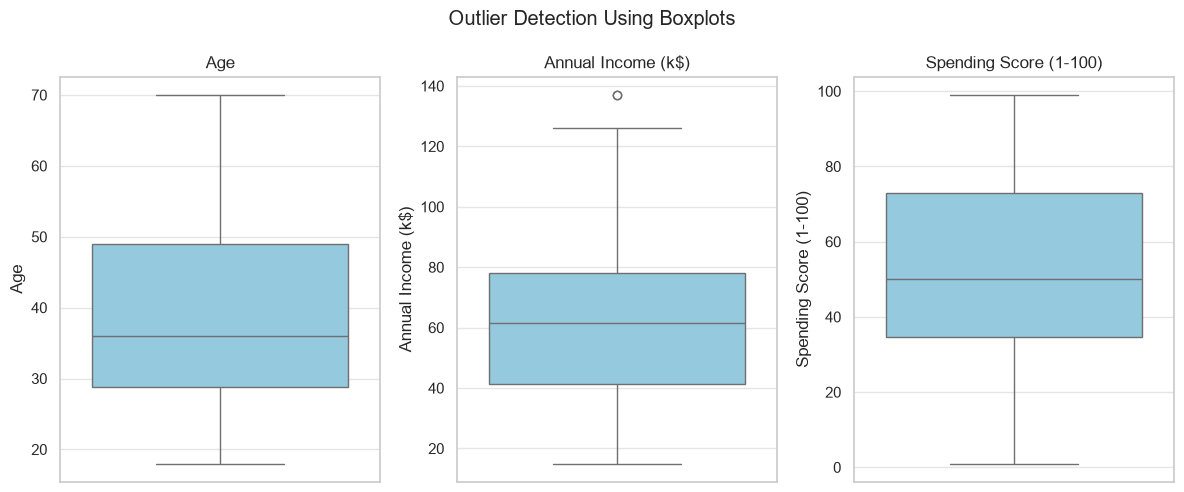

In [218]:
# VISUALISING OUTLIERS USING BOXPLOTS

plt.figure(figsize=(12, 5))

for i, column in enumerate(features_to_check, 1):

    plt.subplot(1, 3, i)

    sns.boxplot(
        y=df_clean[column],
        color='skyblue'
    )

    plt.title(column)

plt.suptitle("Outlier Detection Using Boxplots")

plt.tight_layout()

plt.savefig(
    graph_folder / "15_Outlier_Detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [219]:
# Using the cleaned dataset for further analysis

df = df_clean.copy()

print("Cleaned dataset is ready for preprocessing!")

Cleaned dataset is ready for preprocessing!


In [220]:
# SELECTING FEATURES FOR CUSTOMER SEGMENTATION

features = [
    'Annual Income (k$)',
    'Spending Score (1-100)'
]

X = df[features].copy()

print("Selected Features:")
display(X.head())

print("\nNumber of Features:", len(features))

print("\nTotal Customer Records:", len(X))

Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Number of Features: 2

Total Customer Records: 200


In [221]:
# STANDARDISATION USING STANDARD SCALER

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Converting scaled values into a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print("Original Data:")
display(X.head())

print("\nStandardised Data:")
display(X_scaled_df.head())

print("\nMean After Scaling:")
print(X_scaled_df.mean().round(3))

print("\nStandard Deviation After Scaling:")
print(X_scaled_df.std().round(3))

Original Data:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Standardised Data:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Mean After Scaling:
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Standard Deviation After Scaling:
Annual Income (k$)        1.003
Spending Score (1-100)    1.003
dtype: float64


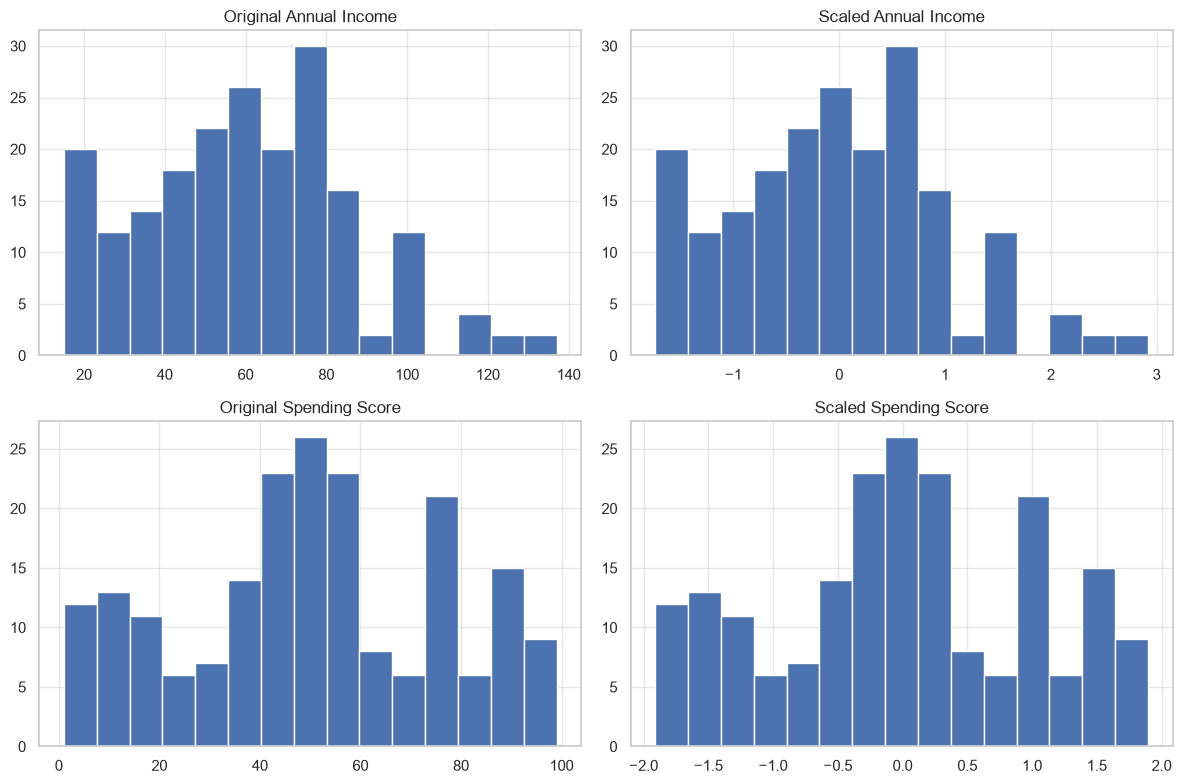

In [222]:
# COMPARING FEATURE DISTRIBUTIONS BEFORE
# AND AFTER STANDARDISATION

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(X['Annual Income (k$)'], bins=15)

axes[0, 0].set_title("Original Annual Income")

axes[0, 1].hist(X_scaled_df['Annual Income (k$)'], bins=15)

axes[0, 1].set_title("Scaled Annual Income")

axes[1, 0].hist(X['Spending Score (1-100)'], bins=15)

axes[1, 0].set_title("Original Spending Score")

axes[1, 1].hist(X_scaled_df['Spending Score (1-100)'], bins=15)

axes[1, 1].set_title("Scaled Spending Score")

plt.tight_layout()

plt.savefig(
    graph_folder / "16_Feature_Scaling_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [223]:
# IMPORTING PERFORMANCE EVALUATION PARAMETERS

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("Performance evaluation metrics imported!")

Performance evaluation metrics imported!


In [224]:
# EVALUATING THE K-MEANS CLUSTERING MODEL

# 1. Inertia
inertia = kmeans.inertia_

# 2. Silhouette Score
silhouette = silhouette_score(
    X_scaled,
    df['Cluster']
)

# 3. Davies-Bouldin Index
davies_bouldin = davies_bouldin_score(
    X_scaled,
    df['Cluster']
)

# 4. Calinski-Harabasz Index
calinski_harabasz = calinski_harabasz_score(
    X_scaled,
    df['Cluster']
)

print("=" * 55)
print("K-MEANS MODEL PERFORMANCE EVALUATION")
print("=" * 55)

print(f"Inertia: {inertia:.2f}")

print(f"Silhouette Score: {silhouette:.4f}")

print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")

print(f"Calinski-Harabasz Index: {calinski_harabasz:.2f}")

KeyError: 'Cluster'

In [ ]:
# CREATING A PERFORMANCE EVALUATION TABLE

performance_results = pd.DataFrame({

    'Performance Parameter': [
        'Inertia (WCSS)',
        'Silhouette Score',
        'Davies-Bouldin Index',
        'Calinski-Harabasz Index'
    ],

    'Calculated Value': [
        inertia,
        silhouette,
        davies_bouldin,
        calinski_harabasz
    ],

    'Preferred Direction': [
        'Lower',
        'Higher',
        'Lower',
        'Higher'
    ]

})

display(performance_results.round(4))

In [ ]:
# COMPARING DIFFERENT CLUSTER COUNTS
# USING MULTIPLE PERFORMANCE PARAMETERS

comparison_results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    comparison_results.append({

        'Number of Clusters': k,

        'Inertia': model.inertia_,

        'Silhouette Score': silhouette_score(
            X_scaled, labels
        ),

        'Davies-Bouldin Index': davies_bouldin_score(
            X_scaled, labels
        ),

        'Calinski-Harabasz Index': calinski_harabasz_score(
            X_scaled, labels
        )

    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

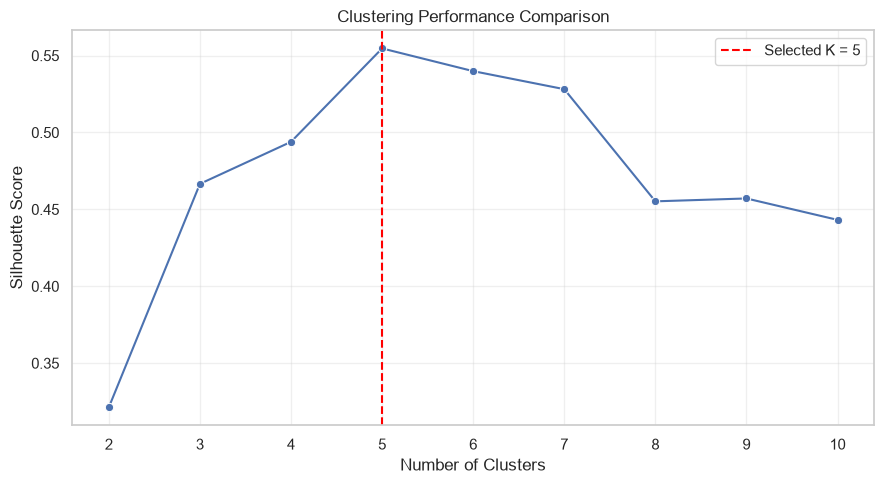

In [225]:
# VISUALISING SILHOUETTE SCORE FOR DIFFERENT K VALUES

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=comparison_df,
    x='Number of Clusters',
    y='Silhouette Score',
    marker='o'
)

plt.axvline(
    x=5,
    linestyle='--',
    color='red',
    label='Selected K = 5'
)

plt.title('Clustering Performance Comparison')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    graph_folder / "17_Performance_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [226]:
#6 Checking whether important numerical features contain
# zero, negative or invalid values.

print("Minimum Annual Income:",
      df['Annual Income (k$)'].min())

print("Minimum Spending Score:",
      df['Spending Score (1-100)'].min())

print("Minimum Age:",
      df['Age'].min())

# Verify required columns

required_columns = [
    'CustomerID',
    'Gender',
    'Age',
    'Annual Income (k$)',
    'Spending Score (1-100)'
]

for column in required_columns:
    assert column in df.columns, f"Missing column: {column}"

# Check missing values in important columns

assert not df[required_columns].isnull().any().any(), \
    "Missing values detected. Clean the dataset before proceeding."

print("\nDataset validation completed!")

Minimum Annual Income: 15
Minimum Spending Score: 1
Minimum Age: 18

Dataset validation completed!


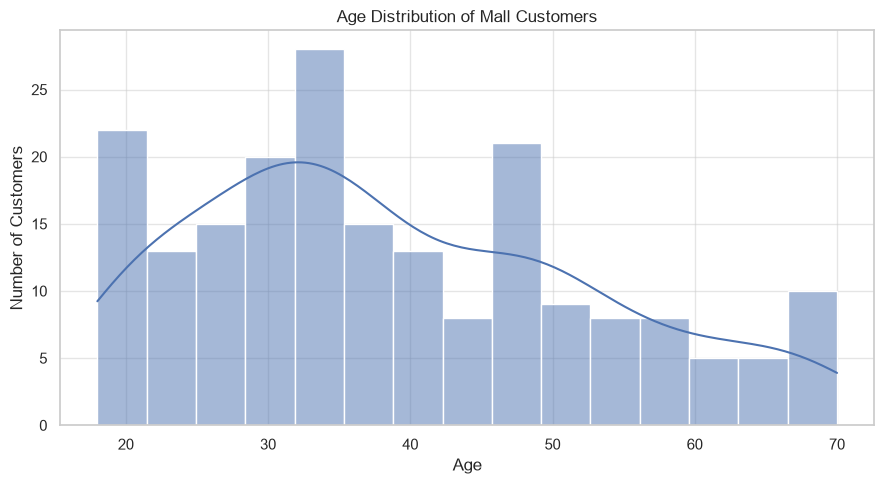

In [227]:
#7 Analysing the age distribution of mall customers.

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Age',
    bins=15,
    kde=True
)

plt.title('Age Distribution of Mall Customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.tight_layout()

plt.savefig(
    graph_folder / "graph_name1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

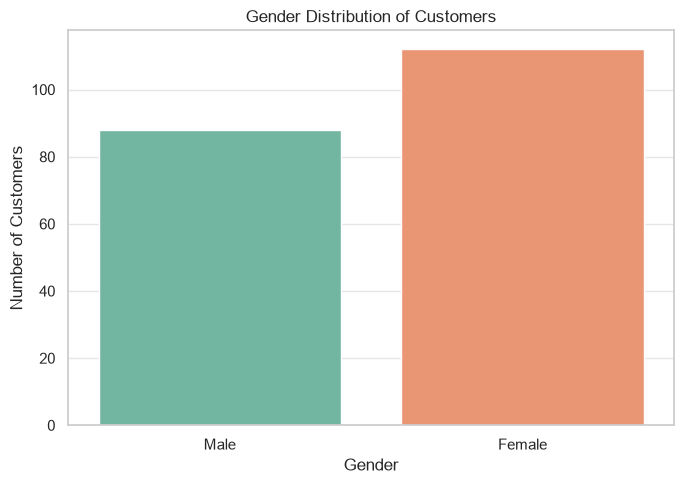


Gender Counts:
Gender
Female    112
Male       88
Name: count, dtype: int64


In [228]:
#8 Analysing the gender composition of customers.

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Gender',
    hue='Gender',
    palette='Set2',
    legend=False
)

plt.title('Gender Distribution of Customers')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.tight_layout()

plt.savefig(
    graph_folder / "graph_name2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGender Counts:")
print(df['Gender'].value_counts())

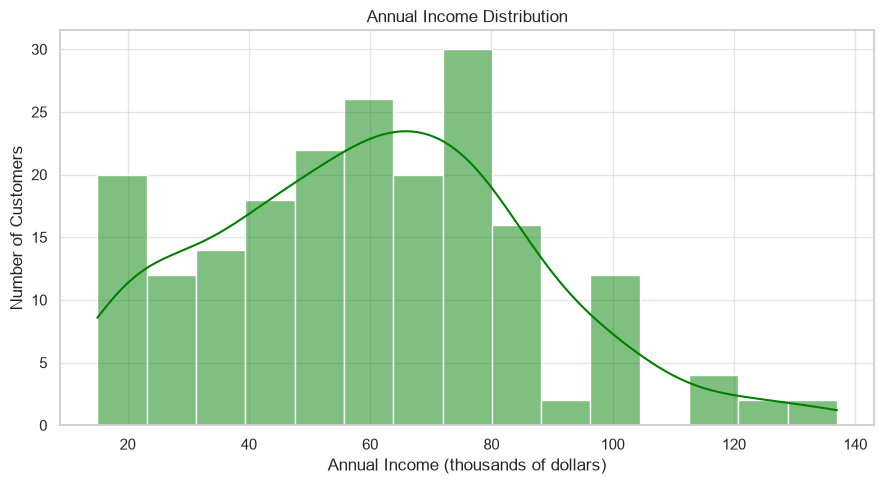

In [229]:
#9 Understanding the annual income distribution.

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Annual Income (k$)',
    bins=15,
    kde=True,
    color='green'
)

plt.title('Annual Income Distribution')
plt.xlabel('Annual Income (thousands of dollars)')
plt.ylabel('Number of Customers')

plt.tight_layout()

plt.savefig(
    graph_folder / "graph_name3.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

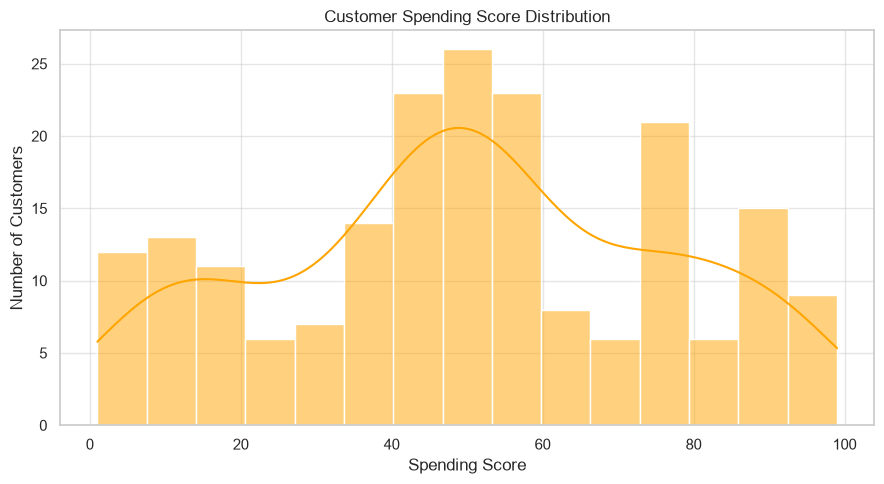

In [230]:
#10 Analysing the spending score of customers.

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Spending Score (1-100)',
    bins=15,
    kde=True,
    color='orange'
)

plt.title('Customer Spending Score Distribution')
plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name4.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

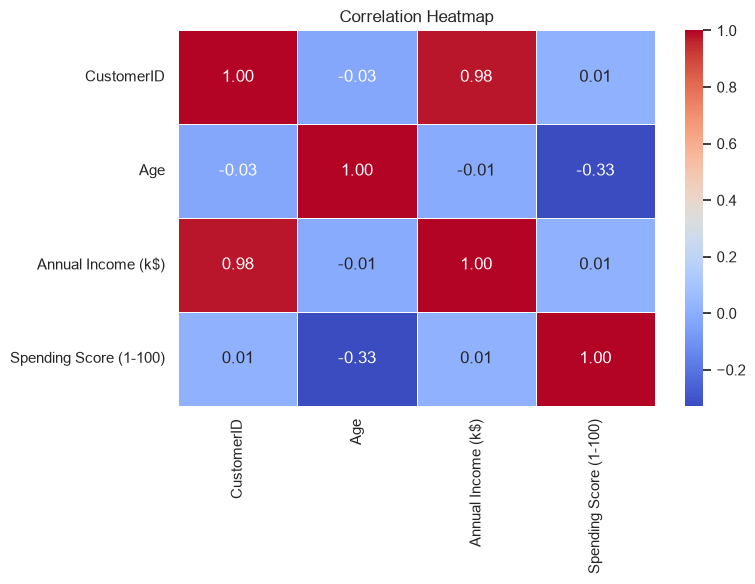

In [231]:
#11 Analysing correlations between numerical variables.

plt.figure(figsize=(8, 6))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name5.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [232]:
#12 Selecting Annual Income and Spending Score
# as the two features for customer segmentation.

features = [
    'Annual Income (k$)',
    'Spending Score (1-100)'
]

X = df[features].copy()

print("Selected Features:")
display(X.head())

print("\nFeature Matrix Shape:")
print(X.shape)

Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Feature Matrix Shape:
(200, 2)


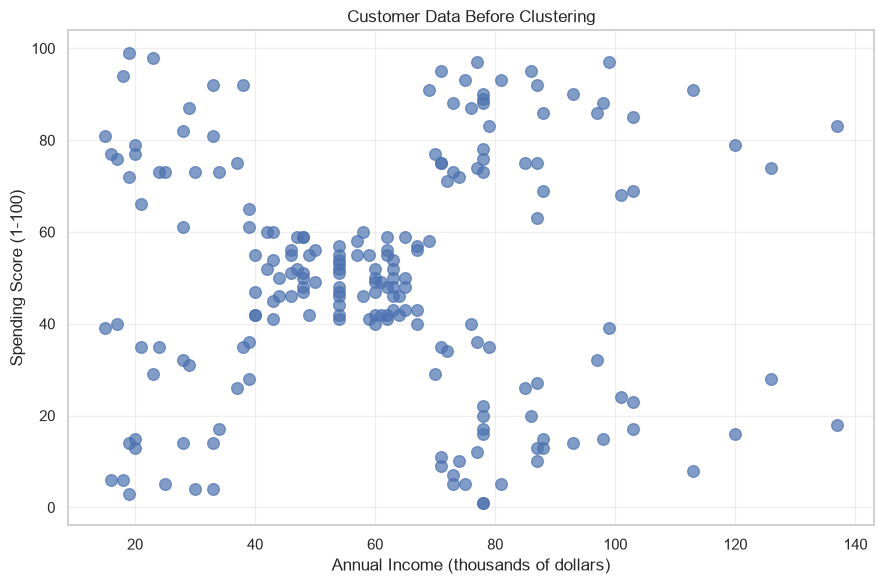

In [233]:
#13 Visualising customer data before applying K-Means.

plt.figure(figsize=(9, 6))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    s=70,
    alpha=0.7
)

plt.title('Customer Data Before Clustering')
plt.xlabel('Annual Income (thousands of dollars)')
plt.ylabel('Spending Score (1-100)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name6.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [234]:
#14 Standardising the selected features using StandardScaler.
# This ensures that both features contribute fairly
# to the distance calculations used by K-Means.

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original Feature Means:")
print(X.mean())

print("\nStandardised Feature Means:")
print(X_scaled.mean(axis=0).round(3))

print("\nStandardisation completed successfully!")

Original Feature Means:
Annual Income (k$)        60.56
Spending Score (1-100)    50.20
dtype: float64

Standardised Feature Means:
[-0. -0.]

Standardisation completed successfully!


In [235]:
#15 Applying K-Means with five clusters.
# Random state ensures reproducible results.

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means model trained successfully!")

print("\nNumber of Customers in Each Cluster:")

print(
    df['Cluster'].value_counts().sort_index()
)

K-Means model trained successfully!

Number of Customers in Each Cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


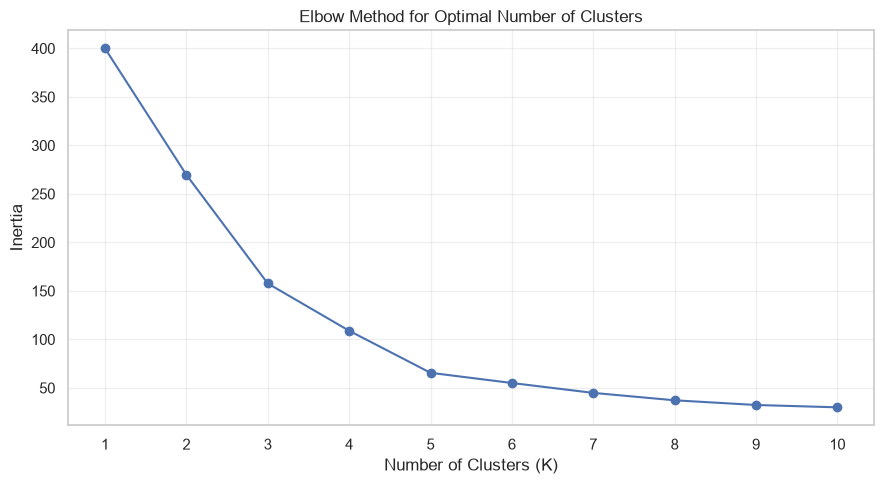

In [236]:
# Using the Elbow Method to identify a suitable
# number of clusters.

k_values = range(1, 11)

inertia_values = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia_values.append(model.inertia_)


plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name7.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

K = 2, Silhouette Score = 0.3213
K = 3, Silhouette Score = 0.4666
K = 4, Silhouette Score = 0.4939
K = 5, Silhouette Score = 0.5547
K = 6, Silhouette Score = 0.5399
K = 7, Silhouette Score = 0.5281
K = 8, Silhouette Score = 0.4552
K = 9, Silhouette Score = 0.4571
K = 10, Silhouette Score = 0.4432


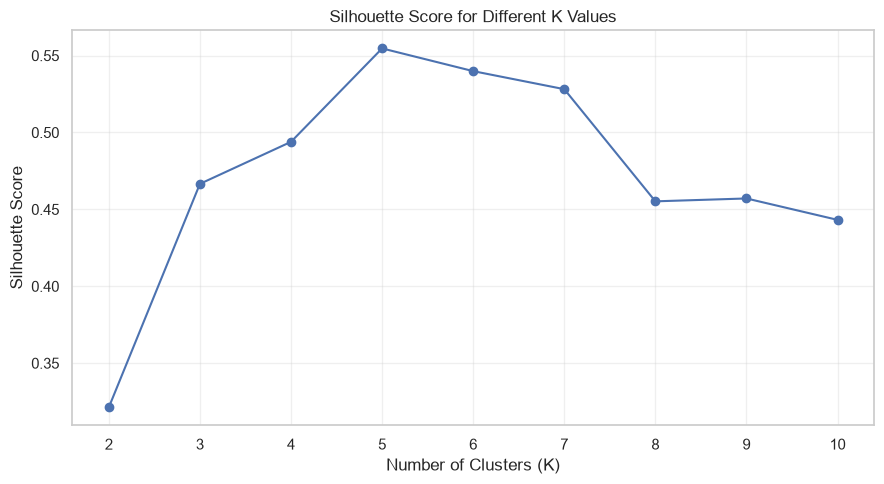


Best K according to Silhouette Score: 5


In [237]:
#18 Evaluating clustering quality for different K values.
# A higher silhouette score generally indicates
# better-separated and more compact clusters.

silhouette_values = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")


plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_values,
    marker='o'
)

plt.title('Silhouette Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.xticks(range(2, 11))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name8.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


best_k = list(range(2, 11))[
    np.argmax(silhouette_values)
]

print("\nBest K according to Silhouette Score:", best_k)

In [238]:
#19 Converting cluster centres back to original
# income and spending score scales.

centres_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centres_df = pd.DataFrame(
    centres_original,
    columns=features
)

print("Cluster Centres:")
display(centres_df.round(2))

Cluster Centres:


,Annual Income (k$),Spending Score (1-100)
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


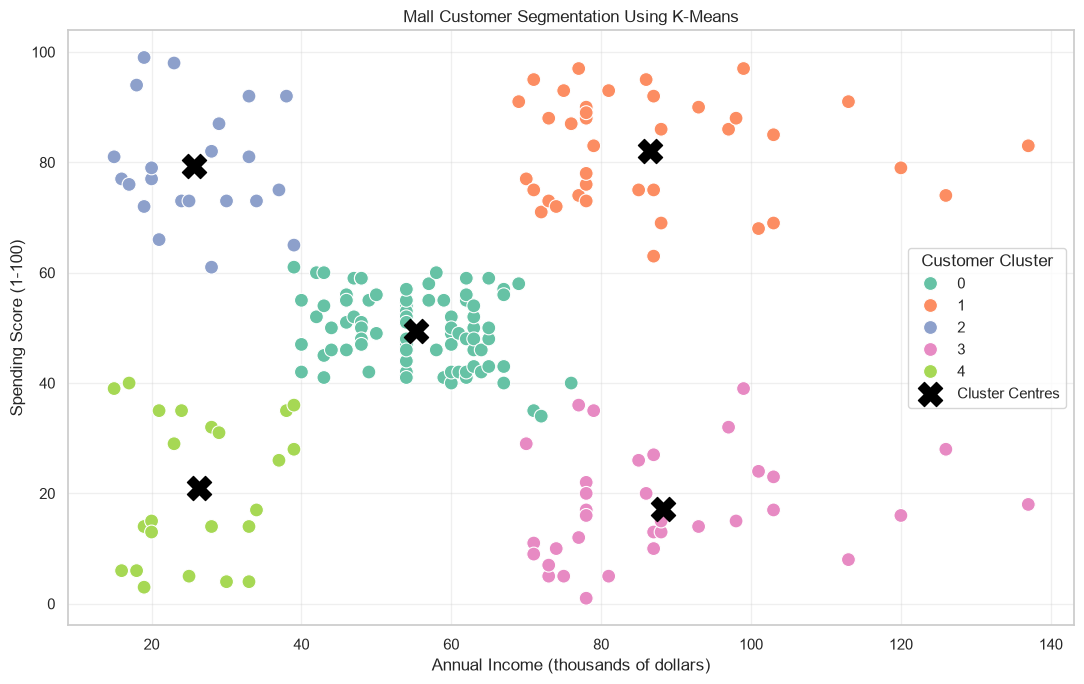

In [239]:
#20 Visualising the five customer segments
# and their corresponding cluster centres.

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set2',
    s=100
)

plt.scatter(
    centres_original[:, 0],
    centres_original[:, 1],
    marker='X',
    s=300,
    color='black',
    label='Cluster Centres'
)

plt.title('Mall Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (thousands of dollars)')
plt.ylabel('Spending Score (1-100)')

plt.legend(title='Customer Cluster')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name9.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [240]:
#21 Calculating the average income, spending score,
# age and number of customers in each cluster.

summary = df.groupby('Cluster').agg(

    Average_Income=(
        'Annual Income (k$)', 'mean'
    ),

    Average_Spending=(
        'Spending Score (1-100)', 'mean'
    ),

    Average_Age=(
        'Age', 'mean'
    ),

    Number_of_Customers=(
        'CustomerID', 'count'
    )

).round(2)

print("Customer Segment Summary:")

display(summary)

Customer Segment Summary:


,Average_Income,Average_Spending,Average_Age,Number_of_Customers
Cluster,,,,
0,55.30,49.52,42.72,81
1,86.54,82.13,32.69,39
2,25.73,79.36,25.27,22
3,88.20,17.11,41.11,35
4,26.30,20.91,45.22,23


In [241]:
#22 Assigning meaningful customer segment names
# based on cluster centre positions.

income_median = X['Annual Income (k$)'].median()

spending_median = X['Spending Score (1-100)'].median()

centres = pd.DataFrame(
    centres_original,
    columns=features
)

# Find the cluster closest to the overall median point.
# This cluster represents average customers.

median_point = np.array([
    income_median,
    spending_median
])

distance_from_median = np.linalg.norm(
    centres.values - median_point,
    axis=1
)

average_cluster = np.argmin(distance_from_median)

cluster_names = {}

for cluster in range(5):

    if cluster == average_cluster:

        name = "Average Customers"

    else:

        income = centres.iloc[cluster, 0]
        spending = centres.iloc[cluster, 1]

        if income >= income_median and spending >= spending_median:

            name = "High-Income High-Spending"

        elif income >= income_median and spending < spending_median:

            name = "High-Income Low-Spending"

        elif income < income_median and spending >= spending_median:

            name = "Low-Income High-Spending"

        else:

            name = "Low-Income Low-Spending"

    cluster_names[cluster] = name


df['Segment'] = df['Cluster'].map(cluster_names)

summary['Segment_Name'] = summary.index.map(cluster_names)

print("Customer Segment Names:")

display(summary)

Customer Segment Names:


,Average_Income,Average_Spending,Average_Age,Number_of_Customers,Segment_Name
Cluster,,,,,
0,55.30,49.52,42.72,81,Average Customers
1,86.54,82.13,32.69,39,High-Income High-Spending
2,25.73,79.36,25.27,22,Low-Income High-Spending
3,88.20,17.11,41.11,35,High-Income Low-Spending
4,26.30,20.91,45.22,23,Low-Income Low-Spending


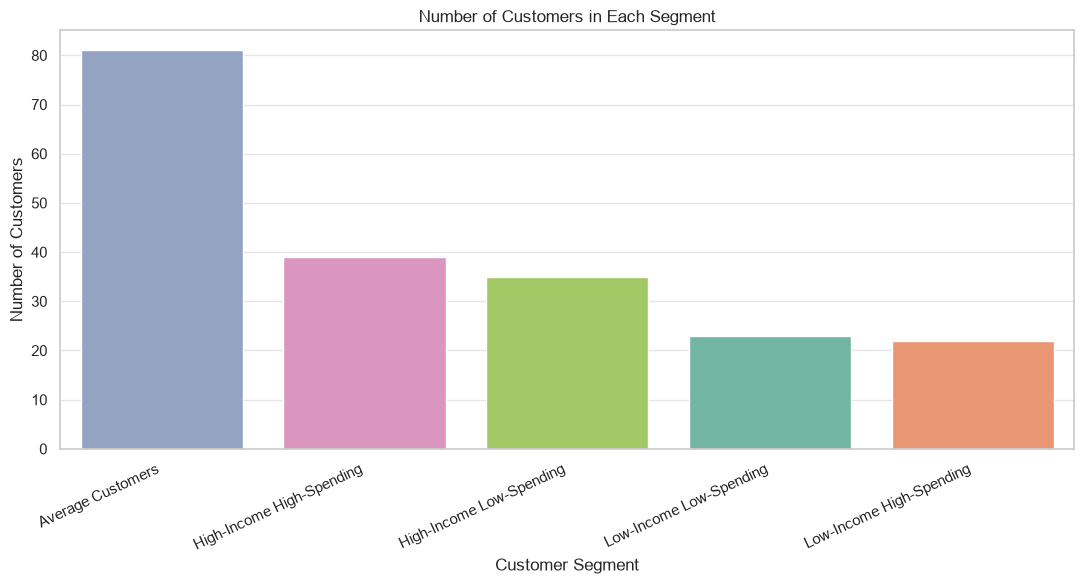

In [242]:
#23 Comparing the sizes of the five customer segments.

plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x='Segment',
    order=df['Segment'].value_counts().index,
    hue='Segment',
    palette='Set2',
    legend=False
)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name10.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

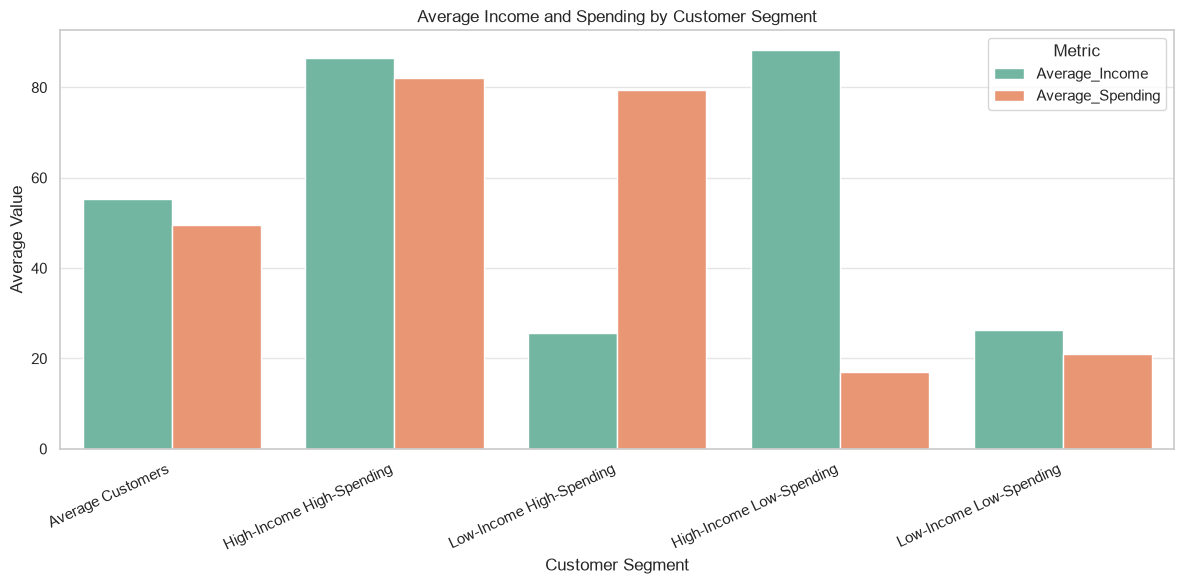

In [243]:
#24 Comparing average income and spending score
# across the five customer segments.

plot_data = summary.reset_index()

plot_data = plot_data.melt(
    id_vars='Segment_Name',
    value_vars=[
        'Average_Income',
        'Average_Spending'
    ],
    var_name='Metric',
    value_name='Average Value'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x='Segment_Name',
    y='Average Value',
    hue='Metric',
    palette='Set2'
)

plt.title('Average Income and Spending by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Value')

plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name11.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

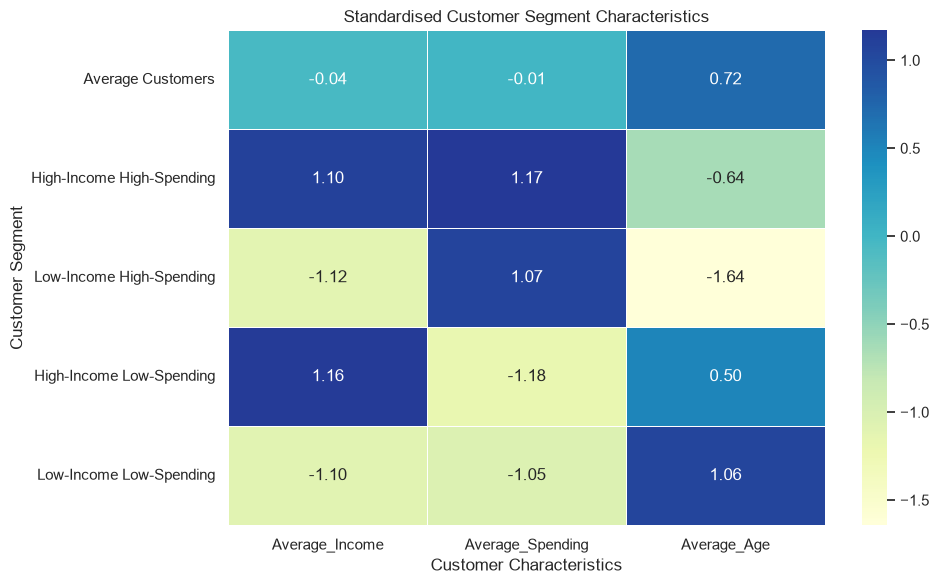

In [244]:
#25 Comparing customer segment characteristics
# using standardised cluster averages.

heatmap_data = summary[
    [
        'Average_Income',
        'Average_Spending',
        'Average_Age'
    ]
]

scaled_heatmap = pd.DataFrame(
    StandardScaler().fit_transform(heatmap_data),
    index=summary['Segment_Name'],
    columns=heatmap_data.columns
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    scaled_heatmap,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    center=0,
    linewidths=0.5
)

plt.title('Standardised Customer Segment Characteristics')
plt.xlabel('Customer Characteristics')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name12.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

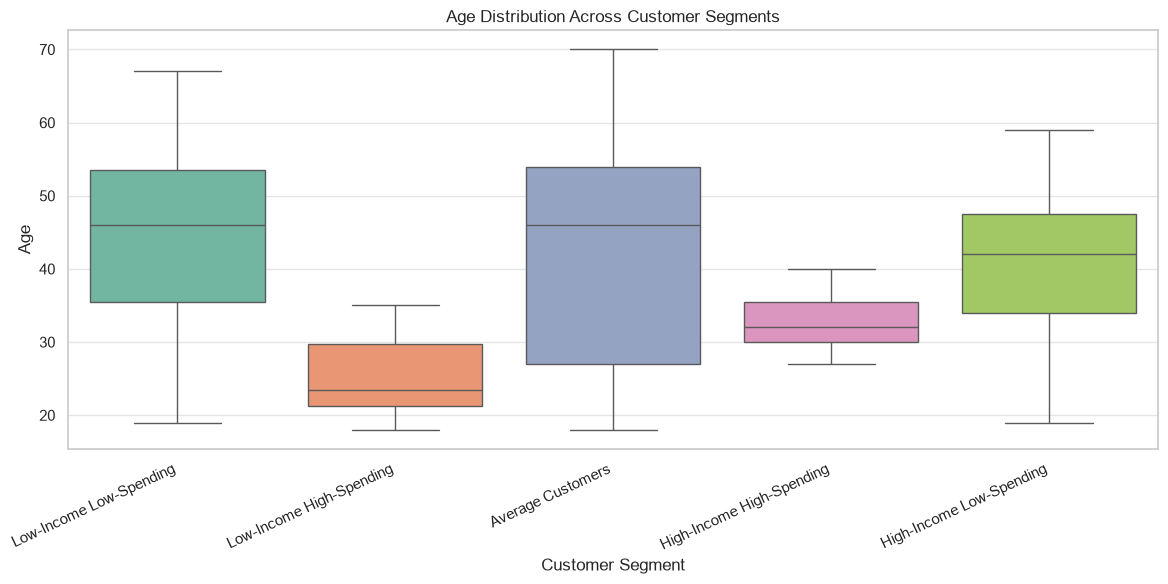

In [245]:
#26 Studying how customer ages are distributed
# across the identified customer segments.

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Segment',
    y='Age',
    hue='Segment',
    palette='Set2',
    legend=False
)

plt.title('Age Distribution Across Customer Segments')
plt.xlabel('Customer Segment')
plt.ylabel('Age')

plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name13.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Gender Distribution Within Each Segment (%):


Gender,Female,Male
Segment,,
Average Customers,59.26,40.74
High-Income High-Spending,53.85,46.15
High-Income Low-Spending,45.71,54.29
Low-Income High-Spending,59.09,40.91
Low-Income Low-Spending,60.87,39.13


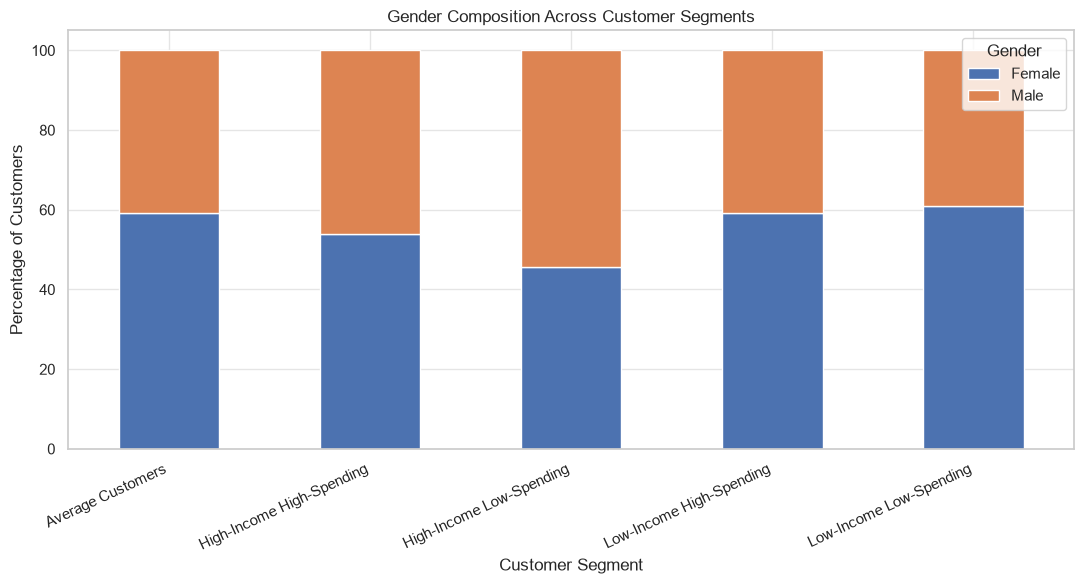

In [246]:
#27 Studying gender composition within each segment.

gender_analysis = pd.crosstab(
    df['Segment'],
    df['Gender'],
    normalize='index'
) * 100

print("Gender Distribution Within Each Segment (%):")

display(gender_analysis.round(2))


gender_analysis.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title('Gender Composition Across Customer Segments')
plt.xlabel('Customer Segment')
plt.ylabel('Percentage of Customers')

plt.xticks(rotation=25, ha='right')

plt.legend(title='Gender')

plt.tight_layout()
plt.savefig(
    graph_folder / "graph_name14.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [247]:
#28 Evaluating the clustering model using
# the Davies-Bouldin Index.

db_score = davies_bouldin_score(
    X_scaled,
    df['Cluster']
)

print("Model Evaluation Results")
print("-" * 35)

print(
    "Silhouette Score:",
    round(silhouette_score(X_scaled, df['Cluster']), 4)
)

print(
    "Davies-Bouldin Score:",
    round(db_score, 4)
)

print(
    "Inertia:",
    round(kmeans.inertia_, 2)
)

Model Evaluation Results
-----------------------------------
Silhouette Score: 0.5547
Davies-Bouldin Score: 0.5722
Inertia: 65.57


In [248]:
#29 Calculating the percentage of customers
# belonging to each segment.

segment_percentage = (
    df['Segment']
    .value_counts(normalize=True) * 100
)

segment_percentage = segment_percentage.round(2)

print("Customer Segment Distribution (%):")

display(segment_percentage.to_frame(
    name='Percentage'
))

Customer Segment Distribution (%):


,Percentage
Segment,
Average Customers,40.5
High-Income High-Spending,19.5
High-Income Low-Spending,17.5
Low-Income Low-Spending,11.5
Low-Income High-Spending,11.0


In [249]:
#30 Testing K-Means performance using different
# random seeds to check model consistency.

random_seeds = [10, 20, 30, 40, 42, 50, 100]

stability_results = []

for seed in random_seeds:

    model = KMeans(
        n_clusters=5,
        random_state=seed,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    stability_results.append({
        'Random Seed': seed,
        'Silhouette Score': score,
        'Inertia': model.inertia_
    })


stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))

print(
    "\nAverage Silhouette Score:",
    round(stability_df['Silhouette Score'].mean(), 4)
)

print(
    "Standard Deviation:",
    round(stability_df['Silhouette Score'].std(), 4)
)

,Random Seed,Silhouette Score,Inertia
0,10,0.5547,65.5684
1,20,0.5547,65.5684
2,30,0.5547,65.5684
3,40,0.5547,65.5684
4,42,0.5547,65.5684
5,50,0.5547,65.5684
6,100,0.5547,65.5684



Average Silhouette Score: 0.5547
Standard Deviation: 0.0


In [250]:
#31 Providing marketing strategies based on
# the characteristics of each customer segment.

recommendations = {

    "High-Income High-Spending":
    "Provide VIP memberships, premium products and exclusive rewards.",

    "High-Income Low-Spending":
    "Use personalised offers and premium product demonstrations.",

    "Low-Income High-Spending":
    "Introduce loyalty points, affordable premium products and rewards.",

    "Low-Income Low-Spending":
    "Provide budget-friendly products and seasonal discounts.",

    "Average Customers":
    "Use seasonal campaigns, membership programs and personalised offers."
}


print("=" * 65)
print("CUSTOMER SEGMENT MARKETING RECOMMENDATIONS")
print("=" * 65)

for cluster, row in summary.iterrows():

    segment = row['Segment_Name']

    recommendation = recommendations[segment]

    print(f"\nCluster {cluster}: {segment}")

    print(
        f"Number of Customers: "
        f"{row['Number_of_Customers']}"
    )

    print(
        f"Average Income: "
        f"{row['Average_Income']}"
    )

    print(
        f"Average Spending: "
        f"{row['Average_Spending']}"
    )

    print("Marketing Strategy:", recommendation)

CUSTOMER SEGMENT MARKETING RECOMMENDATIONS

Cluster 0: Average Customers
Number of Customers: 81
Average Income: 55.3
Average Spending: 49.52
Marketing Strategy: Use seasonal campaigns, membership programs and personalised offers.

Cluster 1: High-Income High-Spending
Number of Customers: 39
Average Income: 86.54
Average Spending: 82.13
Marketing Strategy: Provide VIP memberships, premium products and exclusive rewards.

Cluster 2: Low-Income High-Spending
Number of Customers: 22
Average Income: 25.73
Average Spending: 79.36
Marketing Strategy: Introduce loyalty points, affordable premium products and rewards.

Cluster 3: High-Income Low-Spending
Number of Customers: 35
Average Income: 88.2
Average Spending: 17.11
Marketing Strategy: Use personalised offers and premium product demonstrations.

Cluster 4: Low-Income Low-Spending
Number of Customers: 23
Average Income: 26.3
Average Spending: 20.91
Marketing Strategy: Provide budget-friendly products and seasonal discounts.


In [251]:
#32 Generating important findings from the
# customer segmentation model.

print("=" * 65)
print("FINAL PROJECT FINDINGS")
print("=" * 65)

print("\n1. Dataset Information")

print("Total Customers:", len(df))

print("Number of Features Used:", len(features))

print("\n2. Machine Learning Model")

print("Algorithm: K-Means Clustering")

print("Number of Clusters:", 5)

print("\n3. Model Performance")

print(
    "Silhouette Score:",
    round(silhouette_score(X_scaled, df['Cluster']), 4)
)

print(
    "Davies-Bouldin Score:",
    round(davies_bouldin_score(X_scaled, df['Cluster']), 4)
)

print("\n4. Largest Customer Segment")

largest_segment = df['Segment'].value_counts().idxmax()

print(largest_segment)

print(
    "Number of Customers:",
    df['Segment'].value_counts().max()
)

print("\n5. Smallest Customer Segment")

smallest_segment = df['Segment'].value_counts().idxmin()

print(smallest_segment)

print(
    "Number of Customers:",
    df['Segment'].value_counts().min()
)

print("\n6. Business Application")

print(
    "The segmentation results can help malls develop "
    "targeted marketing strategies for different "
    "customer groups."
)

print("\nProject analysis completed successfully!")

FINAL PROJECT FINDINGS

1. Dataset Information
Total Customers: 200
Number of Features Used: 2

2. Machine Learning Model
Algorithm: K-Means Clustering
Number of Clusters: 5

3. Model Performance
Silhouette Score: 0.5547
Davies-Bouldin Score: 0.5722

4. Largest Customer Segment
Average Customers
Number of Customers: 81

5. Smallest Customer Segment
Low-Income High-Spending
Number of Customers: 22

6. Business Application
The segmentation results can help malls develop targeted marketing strategies for different customer groups.

Project analysis completed successfully!


In [252]:
# Discussing the limitations of the current model
# and possible directions for future improvements.

print("=" * 60)
print("PROJECT LIMITATIONS")
print("=" * 60)

limitations = [

    "The dataset contains only 200 customer records.",

    "The model uses only Annual Income and Spending Score "
    "for clustering.",

    "K-Means requires the number of clusters to be selected "
    "before training.",

    "The results depend on the dataset and selected features.",

    "The model does not include purchase history or "
    "individual customer preferences.",

    "The identified customer segments do not guarantee "
    "future purchasing behaviour."
]

for i, limitation in enumerate(limitations, start=1):

    print(f"{i}. {limitation}")


print("\nFUTURE SCOPE")

future_scope = [

    "Use larger datasets containing more customer records.",

    "Include purchase history and transaction frequency.",

    "Compare K-Means with hierarchical clustering and DBSCAN.",

    "Develop an interactive customer segmentation dashboard.",

    "Use real-time customer data for updated segmentation."
]

for i, item in enumerate(future_scope, start=1):

    print(f"{i}. {item}")

PROJECT LIMITATIONS
1. The dataset contains only 200 customer records.
2. The model uses only Annual Income and Spending Score for clustering.
3. K-Means requires the number of clusters to be selected before training.
4. The results depend on the dataset and selected features.
5. The model does not include purchase history or individual customer preferences.
6. The identified customer segments do not guarantee future purchasing behaviour.

FUTURE SCOPE
1. Use larger datasets containing more customer records.
2. Include purchase history and transaction frequency.
3. Compare K-Means with hierarchical clustering and DBSCAN.
4. Develop an interactive customer segmentation dashboard.
5. Use real-time customer data for updated segmentation.


In [253]:
# Final conclusion of the Customer Segmentation project.

print("""
CONCLUSION

In this project, K-Means clustering was used to analyse
and segment mall customers based on their annual income
and spending score.

The dataset was explored, cleaned and standardised before
applying the machine learning algorithm.

The model divided customers into five distinct groups
with different income and spending characteristics.

The Elbow Method and Silhouette Score were used to
evaluate the clustering process.

The identified customer segments can help businesses
understand customer behaviour and develop targeted
marketing strategies.

This project demonstrates how unsupervised machine
learning can be applied to a practical business problem.

Although the model provides useful insights, future
improvements can include larger datasets, additional
customer characteristics and purchase history.

Overall, the project successfully demonstrates the
application of K-Means clustering for customer
segmentation and business decision-making.
""")


CONCLUSION

In this project, K-Means clustering was used to analyse
and segment mall customers based on their annual income
and spending score.

The dataset was explored, cleaned and standardised before
applying the machine learning algorithm.

The model divided customers into five distinct groups
with different income and spending characteristics.

The Elbow Method and Silhouette Score were used to
evaluate the clustering process.

The identified customer segments can help businesses
understand customer behaviour and develop targeted
marketing strategies.

This project demonstrates how unsupervised machine
learning can be applied to a practical business problem.

Although the model provides useful insights, future
improvements can include larger datasets, additional
customer characteristics and purchase history.

Overall, the project successfully demonstrates the
application of K-Means clustering for customer
segmentation and business decision-making.



In [254]:
# Saving the original dataset with the assigned
# cluster numbers and meaningful segment names.

output_folder = Path("Customer_Segmentation_Results")

output_folder.mkdir(
    parents=True,
    exist_ok=True
)

output_file = output_folder / "Customer_Segmentation.csv"

df.to_csv(
    output_file,
    index=False
)

print("Customer segmentation dataset exported!")

print("File Location:", output_file.resolve())

Customer segmentation dataset exported!
File Location: C:\Users\Tarun\PycharmProjects\WelcomeScreen\Customer_Segmentation_Results\Customer_Segmentation.csv


In [255]:
# Saving the model evaluation metrics
# for the final project report.

evaluation_results = pd.DataFrame({

    'Metric': [
        'Silhouette Score',
        'Davies-Bouldin Score',
        'Inertia',
        'Number of Clusters'
    ],

    'Value': [
        silhouette_score(X_scaled, df['Cluster']),
        db_score,
        kmeans.inertia_,
        5
    ]

})

evaluation_file = output_folder / "Model_Evaluation.csv"

evaluation_results.to_csv(
    evaluation_file,
    index=False
)

display(evaluation_results.round(4))

print("Model evaluation exported successfully!")

,Metric,Value
0,Silhouette Score,0.5547
1,Davies-Bouldin Score,0.5722
2,Inertia,65.5684
3,Number of Clusters,5.0000


Model evaluation exported successfully!


In [256]:
# Verifying all exported project files.

print("=" * 60)
print("PROJECT EXPORT VERIFICATION")
print("=" * 60)

for file in output_folder.iterdir():

    print(
        file.name,
        "-",
        "Successfully created" if file.exists() else "Missing"
    )

print("\nAll project export operations completed!")

PROJECT EXPORT VERIFICATION
Customer_Segmentation.csv - Successfully created
Graphs - Successfully created
Model_Evaluation.csv - Successfully created

All project export operations completed!
